# Go For It: Predicting NFL Fourth-Down Conversions and Evaluating Coaching Decisions
**Keaton Ludwig**

This notebook reproduces every number and figure in the final white paper, presentation, and Q&A. It runs top to bottom:
1. Load nflverse play-by-play (2016–2025) and document data preparation
2. RQ1 — Predict fourth-down conversion; compare models to a distance-only baseline
3. RQ2 — Which factors matter once distance is accounted for
4. RQ3 — Win-probability decision analysis with bootstrapped uncertainty

Data: nflverse play-by-play releases (CC BY 4.0), https://github.com/nflverse/nflverse-data/releases/tag/pbp
6. Extensions — sensitivity checks and the analyses behind the audience Q&A


In [1]:
import os, urllib.request, warnings, time
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import SplineTransformer, StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
import xgboost as xgb
warnings.filterwarnings('ignore')
SEED = 680
rng = np.random.default_rng(SEED)
DATA_DIR = os.environ.get('PBP_DIR', 'data')
FIG_DIR = os.environ.get('FIG_DIR', 'figures')
os.makedirs(DATA_DIR, exist_ok=True); os.makedirs(FIG_DIR, exist_ok=True)
SEASONS = list(range(2016, 2026))
BLUE, ORANGE, GRAY, INK, INK2 = '#2a78d6', '#eb6834', '#9a9893', '#0b0b0b', '#52514e'
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 9, 'axes.edgecolor': '#c3c2b7',
                     'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2,
                     'axes.spines.top': False, 'axes.spines.right': False})

## 1. Load data
One parquet file per season, cached locally after the first download.

In [2]:
COLS = ['game_id','play_id','season','season_type','week','game_date','home_team','away_team','posteam','defteam',
        'posteam_type','qtr','down','ydstogo','yardline_100','goal_to_go','game_seconds_remaining',
        'half_seconds_remaining','score_differential','posteam_timeouts_remaining','defteam_timeouts_remaining',
        'play_type','desc','yards_gained','fourth_down_converted','fourth_down_failed','touchdown','shotgun',
        'no_huddle','pass','rush','roof','surface','temp','wind','spread_line','total_line','result',
        'home_opening_kickoff','kick_distance','field_goal_result','wp','vegas_wp','ep','div_game','penalty']
frames = []
for s in SEASONS:
    f = os.path.join(DATA_DIR, f'pbp_{s}.parquet')
    if not os.path.exists(f):
        urllib.request.urlretrieve(f'https://github.com/nflverse/nflverse-data/releases/download/pbp/play_by_play_{s}.parquet', f)
    frames.append(pd.read_parquet(f, columns=COLS))
pbp = pd.concat(frames, ignore_index=True)
print(f'{len(pbp):,} plays, {pbp.game_id.nunique():,} games, seasons {pbp.season.min()}-{pbp.season.max()}')
print('duplicate (game_id, play_id) keys:', pbp.duplicated(['game_id','play_id']).sum())

484,254 plays, 2,761 games, seasons 2016-2025
duplicate (game_id, play_id) keys: 0


## 2. Data preparation
Derived fields, all knowable **before the snap**:
* `posteam_spread` — Vegas point spread from the offense's view (positive = offense favored)
* `indoor` — dome or closed roof; `turf` — any artificial surface
* `temp_f`, `wind_mph` — set to 70°F / 0 mph indoors (where nflverse leaves them blank by design); remaining outdoor gaps get a missing flag and the season median
* `posteam_won` — game outcome label for the win-probability model (ties dropped)

In [3]:
d = pbp.copy()
d['posteam_home'] = (d.posteam == d.home_team).astype(int)
d['posteam_spread'] = np.where(d.posteam_home == 1, d.spread_line, -d.spread_line)
d['indoor'] = d.roof.isin(['dome', 'closed']).astype(int)
d['turf'] = (~d.surface.fillna('').str.strip().isin(['grass', ''])).astype(int)
d['weather_missing'] = ((d.indoor == 0) & d.temp.isna()).astype(int)
d['temp_f'] = np.where(d.indoor == 1, 70, d.temp)
d['wind_mph'] = np.where(d.indoor == 1, 0, d.wind)
for c in ['temp_f', 'wind_mph']:
    d[c] = d[c].fillna(d.groupby('season')[c].transform('median'))
d['is_fake'] = d.desc.str.contains('Punt formation|Field Goal formation', case=False, na=False) & d.play_type.isin(['pass', 'run'])
d['posteam_won'] = np.select([d.result.eq(0) | d.result.isna(), d.posteam_home.eq(1)], [np.nan, (d.result > 0).astype(float)],
                             (d.result < 0).astype(float))

fourth = d[(d.down == 4) & d.play_type.isin(['pass', 'run', 'punt', 'field_goal'])].copy()
fourth['decision'] = np.where(fourth.play_type.isin(['pass', 'run']), 'go', fourth.play_type)
att = fourth[(fourth.decision == 'go') & ~fourth.is_fake & fourth.fourth_down_converted.notna()].copy()
att['converted'] = att.fourth_down_converted.astype(int)
prep_log = pd.DataFrame({
    'step': ['All plays', 'Fourth-down plays with a go/punt/FG decision (no-plays, kneels, spikes removed)',
             'Go-for-it attempts', 'Fake punts / field goals removed from conversion model', 'Modeling set (attempts)'],
    'rows': [len(d), len(fourth), (fourth.decision == 'go').sum(), int(fourth.is_fake.sum()), len(att)]})
print(prep_log.to_string(index=False))
print('\nConversion rate:', round(att.converted.mean(), 3), '| outdoor attempts with missing weather (imputed):', int(att.weather_missing.sum()))

                                                                           step   rows
                                                                      All plays 484254
Fourth-down plays with a go/punt/FG decision (no-plays, kneels, spikes removed)  39358
                                                             Go-for-it attempts   7049
                         Fake punts / field goals removed from conversion model    264
                                                        Modeling set (attempts)   6785

Conversion rate: 0.531 | outdoor attempts with missing weather (imputed): 420


### Figure 1 — The league has become more aggressive

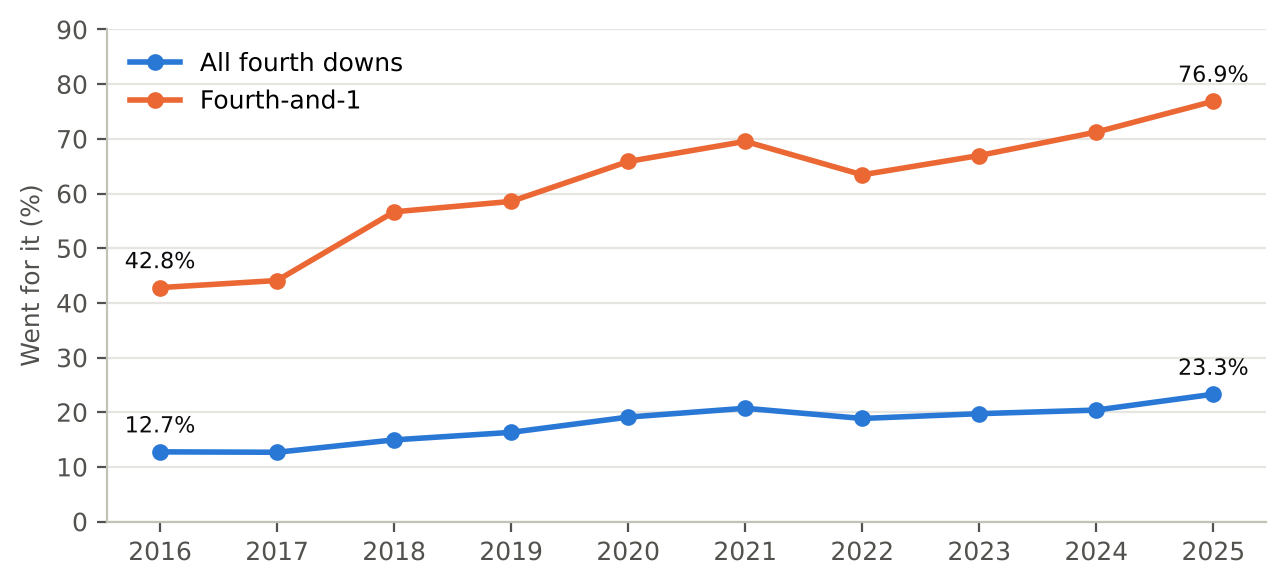

season     2016  2017  2018  2019  2020  2021  2022  2023  2024  2025
all        12.7  12.7  14.9  16.3  19.1  20.7  18.9  19.7  20.4  23.3
4th_and_1  42.8  44.1  56.7  58.6  65.9  69.5  63.4  67.0  71.2  76.9


In [4]:
gr = fourth.assign(go=fourth.decision.eq('go')).groupby('season').go.mean() * 100
g1 = fourth[fourth.ydstogo == 1].assign(go=lambda x: x.decision.eq('go')).groupby('season').go.mean() * 100
fig, ax = plt.subplots(figsize=(6.5, 3.0), dpi=200)
ax.plot(gr.index, gr.values, color=BLUE, lw=2, marker='o', ms=5, label='All fourth downs')
ax.plot(g1.index, g1.values, color=ORANGE, lw=2, marker='o', ms=5, label='Fourth-and-1')
for s, v, c in [(2016, gr[2016], BLUE), (2025, gr[2025], BLUE), (2016, g1[2016], ORANGE), (2025, g1[2025], ORANGE)]:
    ax.annotate(f'{v:.1f}%', (s, v), textcoords='offset points', xytext=(0, 7), ha='center', fontsize=8, color=INK)
ax.set_ylabel('Went for it (%)'); ax.set_ylim(0, 90); ax.set_xticks(SEASONS)
ax.grid(axis='y', color='#e6e5e1', lw=0.8); ax.set_axisbelow(True); ax.legend(frameon=False, loc='upper left')
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/fig1_go_rate.png'); plt.show()
print(pd.DataFrame({'all': gr.round(1), '4th_and_1': g1.round(1)}).T.to_string())

## 3. RQ1 — Predicting conversion
**Split:** strictly by season. Tune on 2024 after training on 2016–2023, then refit on 2016–2024 and test once on 2025.
Forward-chaining (rolling-origin) validation over 2021–2025 checks that results are not specific to one season.

**Features (situation only, no play call):** the main model uses only what is known when the coach decides to go,
so it can later score situations where the team kicked (RQ3). Play-call variables are tested separately in RQ2.

In [5]:
SIT = ['ydstogo', 'yardline_100', 'score_differential', 'game_seconds_remaining', 'half_seconds_remaining',
       'posteam_timeouts_remaining', 'defteam_timeouts_remaining', 'goal_to_go', 'posteam_spread', 'total_line',
       'posteam_home', 'indoor', 'turf', 'temp_f', 'wind_mph', 'weather_missing', 'div_game']
CALL = ['pass', 'shotgun', 'no_huddle']

def baseline_fit(train):
    # empirical conversion rate by yards to go (11+ pooled), Laplace-smoothed toward the overall rate
    b = train.assign(ytg=train.ydstogo.clip(upper=11)).groupby('ytg').converted.agg(['sum', 'count'])
    prior = train.converted.mean(); k = 5
    return ((b['sum'] + k * prior) / (b['count'] + k)).to_dict(), prior

def baseline_pred(model, df):
    table, prior = model
    return df.ydstogo.clip(upper=11).map(table).fillna(prior).values

def make_logit(feats):
    spline = ['ydstogo', 'yardline_100', 'score_differential', 'game_seconds_remaining']
    pre = ColumnTransformer([('spl', SplineTransformer(n_knots=5, degree=3), [f for f in spline if f in feats]),
                             ('lin', StandardScaler(), [f for f in feats if f not in spline])])
    return Pipeline([('pre', pre), ('lr', LogisticRegression(C=1.0, max_iter=2000))])

def make_rf():
    return RandomForestClassifier(n_estimators=400, min_samples_leaf=40, max_features=0.5, n_jobs=-1, random_state=SEED)

def make_xgb(**kw):
    p = dict(n_estimators=300, learning_rate=0.03, max_depth=3, min_child_weight=10, subsample=0.8,
             colsample_bytree=0.8, reg_lambda=5, objective='binary:logistic', eval_metric='logloss',
             tree_method='hist', n_jobs=2, random_state=SEED)
    p.update(kw); return xgb.XGBClassifier(**p)

def scores(y, p):
    p = np.clip(p, 1e-4, 1 - 1e-4)
    return {'Brier': brier_score_loss(y, p), 'LogLoss': log_loss(y, p), 'AUC': roc_auc_score(y, p)}

### Tuning on 2024 (train 2016–2023)

In [6]:
tr, va = att[att.season <= 2023], att[att.season == 2024]
grid = []
for depth in [2, 3, 4]:
    for n in [200, 400]:
        m = make_xgb(max_depth=depth, n_estimators=n).fit(tr[SIT], tr.converted)
        grid.append({'model': f'XGB depth={depth} n={n}', **scores(va.converted, m.predict_proba(va[SIT])[:, 1])})
for C in [0.1, 1.0]:
    m = make_logit(SIT); m.set_params(lr__C=C); m.fit(tr[SIT], tr.converted)
    grid.append({'model': f'Logit C={C}', **scores(va.converted, m.predict_proba(va[SIT])[:, 1])})
for leaf in [20, 40, 80]:
    m = make_rf(); m.set_params(min_samples_leaf=leaf); m.fit(tr[SIT], tr.converted)
    grid.append({'model': f'RF leaf={leaf}', **scores(va.converted, m.predict_proba(va[SIT])[:, 1])})
grid.append({'model': 'Baseline (yards to go)', **scores(va.converted, baseline_pred(baseline_fit(tr), va))})
tune = pd.DataFrame(grid).sort_values('Brier')
print(tune.round(4).to_string(index=False))

                 model  Brier  LogLoss    AUC
     XGB depth=2 n=200 0.2218   0.6346 0.6735
Baseline (yards to go) 0.2222   0.6359 0.6725
     XGB depth=3 n=200 0.2225   0.6361 0.6711
     XGB depth=2 n=400 0.2225   0.6359 0.6693
            RF leaf=80 0.2230   0.6377 0.6732
            RF leaf=40 0.2232   0.6384 0.6714
     XGB depth=3 n=400 0.2240   0.6391 0.6639
     XGB depth=4 n=200 0.2242   0.6397 0.6654
           Logit C=1.0 0.2247   0.6408 0.6592
            RF leaf=20 0.2248   0.6418 0.6659
     XGB depth=4 n=400 0.2262   0.6443 0.6587
           Logit C=0.1 0.2266   0.6451 0.6504


In [7]:
best_xgb = tune[tune.model.str.startswith('XGB')].iloc[0].model
XD = int(best_xgb.split('depth=')[1].split()[0]); XN = int(best_xgb.split('n=')[1])
best_rf_leaf = int(tune[tune.model.str.startswith('RF')].iloc[0].model.split('=')[1])
best_C = float(tune[tune.model.str.startswith('Logit')].iloc[0].model.split('=')[1])
print('Selected:', best_xgb, '| RF leaf', best_rf_leaf, '| Logit C', best_C)

def fit_all(train, feats=SIT):
    lg = make_logit(feats); lg.set_params(lr__C=best_C); lg.fit(train[feats], train.converted)
    rf = make_rf(); rf.set_params(min_samples_leaf=best_rf_leaf); rf.fit(train[feats], train.converted)
    xg = make_xgb(max_depth=XD, n_estimators=XN).fit(train[feats], train.converted)
    return {'Baseline': baseline_fit(train), 'Logistic (splines)': lg, 'Random forest': rf, 'XGBoost': xg}

def predict(name, model, df, feats=SIT):
    return baseline_pred(model, df) if name == 'Baseline' else model.predict_proba(df[feats])[:, 1]

Selected: XGB depth=2 n=200 | RF leaf 80 | Logit C 1.0


### Held-out test: train 2016–2024, test 2025

In [8]:
train, test = att[att.season <= 2024], att[att.season == 2025]
models = fit_all(train)
preds = {k: predict(k, m, test) for k, m in models.items()}
test_tbl = pd.DataFrame({k: scores(test.converted, p) for k, p in preds.items()}).T
test_tbl['Brier skill vs baseline (%)'] = (1 - test_tbl.Brier / test_tbl.loc['Baseline', 'Brier']) * 100
print(f'Test set: {len(test):,} attempts, {test.converted.mean():.3f} converted')
print(test_tbl.round(4).to_string())

Test set: 917 attempts, 0.552 converted
                     Brier  LogLoss     AUC  Brier skill vs baseline (%)
Baseline            0.2295   0.6513  0.6409                       0.0000
Logistic (splines)  0.2259   0.6428  0.6593                       1.5695
Random forest       0.2272   0.6456  0.6531                       0.9871
XGBoost             0.2267   0.6443  0.6542                       1.2181


Paired bootstrap (resampling **games**) for the Brier difference between each model and the baseline on 2025.

In [9]:
def game_boot_diff(df, p_model, p_base, B=2000):
    g = df.game_id.values; ug = np.unique(g); idx = {u: np.where(g == u)[0] for u in ug}
    y = df.converted.values; diffs = []
    for _ in range(B):
        ii = np.concatenate([idx[u] for u in rng.choice(ug, len(ug))])
        diffs.append(np.mean((p_model[ii] - y[ii]) ** 2) - np.mean((p_base[ii] - y[ii]) ** 2))
    return np.percentile(diffs, [2.5, 50, 97.5]), np.mean(np.array(diffs) < 0)
boot_rows = []
for k in ['Logistic (splines)', 'Random forest', 'XGBoost']:
    ci, pr = game_boot_diff(test, preds[k], preds['Baseline'])
    boot_rows.append({'model': k, 'Brier diff (model - baseline)': ci[1], 'CI 2.5%': ci[0], 'CI 97.5%': ci[2], 'P(model better)': pr})
boot_tbl = pd.DataFrame(boot_rows); print(boot_tbl.round(4).to_string(index=False))

             model  Brier diff (model - baseline)  CI 2.5%  CI 97.5%  P(model better)
Logistic (splines)                        -0.0037  -0.0079    0.0003            0.964
     Random forest                        -0.0023  -0.0055    0.0008            0.925
           XGBoost                        -0.0027  -0.0061    0.0005            0.957


### Forward-chaining validation (train on all prior seasons, test the next), 2021–2025

In [10]:
fc = []
for s in range(2021, 2026):
    trn, tst = att[att.season < s], att[att.season == s]
    ms = fit_all(trn)
    for k, m in ms.items():
        fc.append({'test_season': s, 'model': k, 'n': len(tst), **scores(tst.converted, predict(k, m, tst))})
fc = pd.DataFrame(fc)
fc_sum = fc.groupby('model')[['Brier', 'LogLoss', 'AUC']].mean().sort_values('Brier')
fc_sum['seasons model beat baseline (Brier)'] = [
    int((fc[fc.model == k].set_index('test_season').Brier < fc[fc.model == 'Baseline'].set_index('test_season').Brier).sum()) for k in fc_sum.index]
print(fc.pivot(index='test_season', columns='model', values='Brier').round(4).to_string())
print(); print(fc_sum.round(4).to_string())

model        Baseline  Logistic (splines)  Random forest  XGBoost
test_season                                                      
2021           0.2278              0.2323         0.2308   0.2310
2022           0.2284              0.2289         0.2297   0.2286
2023           0.2174              0.2177         0.2165   0.2166
2024           0.2222              0.2247         0.2230   0.2218
2025           0.2295              0.2259         0.2272   0.2267

                     Brier  LogLoss     AUC  seasons model beat baseline (Brier)
model                                                                           
XGBoost             0.2249   0.6407  0.6687                                    3
Baseline            0.2251   0.6415  0.6676                                    0
Random forest       0.2254   0.6421  0.6680                                    2
Logistic (splines)  0.2259   0.6425  0.6617                                    1


### Figure 2 — Calibration on the 2025 test season

Model carried forward (chosen on 2024 validation): XGBoost


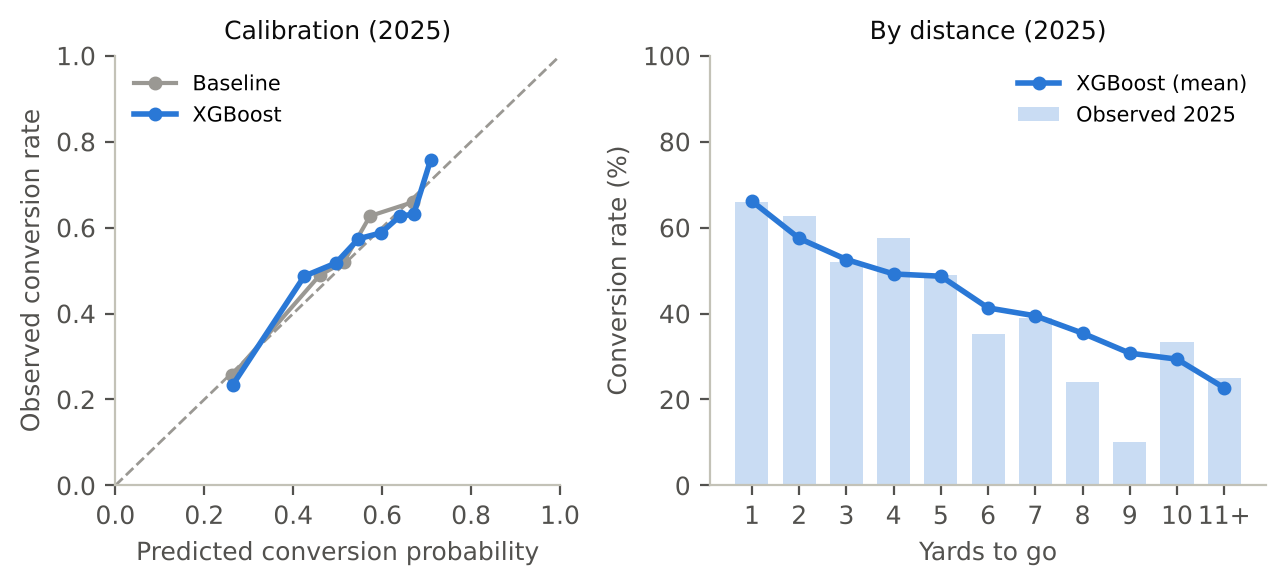

In [11]:
# model family chosen on the 2024 validation season (never on the test season)
_top = tune[tune.model != 'Baseline (yards to go)'].iloc[0].model
best_name = 'XGBoost' if _top.startswith('XGB') else ('Random forest' if _top.startswith('RF') else 'Logistic (splines)')
print('Model carried forward (chosen on 2024 validation):', best_name)
fig, axes = plt.subplots(1, 2, figsize=(6.5, 3.0), dpi=200, gridspec_kw={'width_ratios': [1, 1.25]})
ax = axes[0]
ax.plot([0, 1], [0, 1], color=GRAY, lw=1, ls='--')
for k, c in [('Baseline', GRAY), (best_name, BLUE)]:
    fy, fx = calibration_curve(test.converted, preds[k], n_bins=8, strategy='quantile')
    ax.plot(fx, fy, marker='o', ms=4, lw=2 if k != 'Baseline' else 1.5, color=c, label=k)
ax.set_xlabel('Predicted conversion probability'); ax.set_ylabel('Observed conversion rate')
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.legend(frameon=False, fontsize=7.5, loc='upper left'); ax.set_title('Calibration (2025)', fontsize=9, color=INK)
ax = axes[1]
t2 = test.assign(p=preds[best_name], ytg=test.ydstogo.clip(upper=11))
agg = t2.groupby('ytg').agg(obs=('converted', 'mean'), pred=('p', 'mean'), n=('converted', 'size'))
ax.bar(agg.index, agg.obs * 100, color='#c9dcf3', width=0.7, label='Observed 2025')
ax.plot(agg.index, agg.pred * 100, color=BLUE, marker='o', ms=4, lw=2, label=f'{best_name} (mean)')
ax.set_xticks(range(1, 12)); ax.set_xticklabels([str(i) for i in range(1, 11)] + ['11+'])
ax.set_xlabel('Yards to go'); ax.set_ylabel('Conversion rate (%)'); ax.set_ylim(0, 100)
ax.legend(frameon=False, fontsize=7.5); ax.set_title('By distance (2025)', fontsize=9, color=INK)
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/fig2_calibration.png'); plt.show()

## 4. RQ2 — Which factors matter?
Permutation importance on the 2025 test set (increase in log loss when a feature is shuffled, 30 repeats),
then a second model that adds the play call (pass vs run, shotgun, no-huddle) to see how much it adds.

In [12]:
best_model = models[best_name]
pi = permutation_importance(best_model, test[SIT], test.converted, scoring='neg_log_loss', n_repeats=30, random_state=SEED, n_jobs=1)
imp = pd.DataFrame({'feature': SIT, 'importance': pi.importances_mean, 'sd': pi.importances_std}).sort_values('importance', ascending=False)
print(imp.round(5).to_string(index=False))

                   feature  importance      sd
                   ydstogo     0.06750 0.00789
    half_seconds_remaining     0.00438 0.00127
                total_line     0.00337 0.00180
              yardline_100     0.00187 0.00115
            posteam_spread     0.00125 0.00099
                goal_to_go     0.00028 0.00028
              posteam_home     0.00021 0.00012
        score_differential     0.00018 0.00047
                    indoor     0.00017 0.00011
posteam_timeouts_remaining     0.00014 0.00021
                  div_game     0.00004 0.00009
                      turf     0.00000 0.00000
           weather_missing     0.00000 0.00000
defteam_timeouts_remaining    -0.00000 0.00006
                    temp_f    -0.00019 0.00041
    game_seconds_remaining    -0.00045 0.00044
                  wind_mph    -0.00114 0.00106


In [13]:
models_call = fit_all(train, SIT + CALL)
call_tbl = pd.DataFrame({k: scores(test.converted, predict(k, m, test, SIT + CALL)) for k, m in models_call.items() if k != 'Baseline'}).T
print('With play-call features (2025 test):'); print(call_tbl.round(4).to_string())
pi2 = permutation_importance(models_call[best_name], test[SIT + CALL], test.converted, scoring='neg_log_loss', n_repeats=30, random_state=SEED, n_jobs=1)
imp2 = pd.DataFrame({'feature': SIT + CALL, 'importance': pi2.importances_mean}).sort_values('importance', ascending=False)
print(imp2.head(8).round(5).to_string(index=False))
# run vs pass conversion within short yardage
sy = att.assign(ytg=att.ydstogo.clip(upper=6)).groupby(['ytg', 'pass']).converted.agg(['mean', 'size']).unstack()
print(sy.round(3).to_string())

With play-call features (2025 test):
                     Brier  LogLoss     AUC
Logistic (splines)  0.2248   0.6405  0.6679
Random forest       0.2260   0.6430  0.6616
XGBoost             0.2251   0.6410  0.6646


               feature  importance
               ydstogo     0.05764
half_seconds_remaining     0.00424
            total_line     0.00393
                  pass     0.00313
          yardline_100     0.00146
        posteam_spread     0.00108
            goal_to_go     0.00054
    score_differential     0.00033
       mean         size      
pass    0.0    1.0   0.0   1.0
ytg                           
1.0   0.703  0.580  1969   762
2.0   0.586  0.579   174   768
3.0   0.414  0.519    29   599
4.0   0.333  0.506    15   482
5.0   0.500  0.475    10   377
6.0   0.062  0.301    32  1568


### Figure 3 — Feature importance

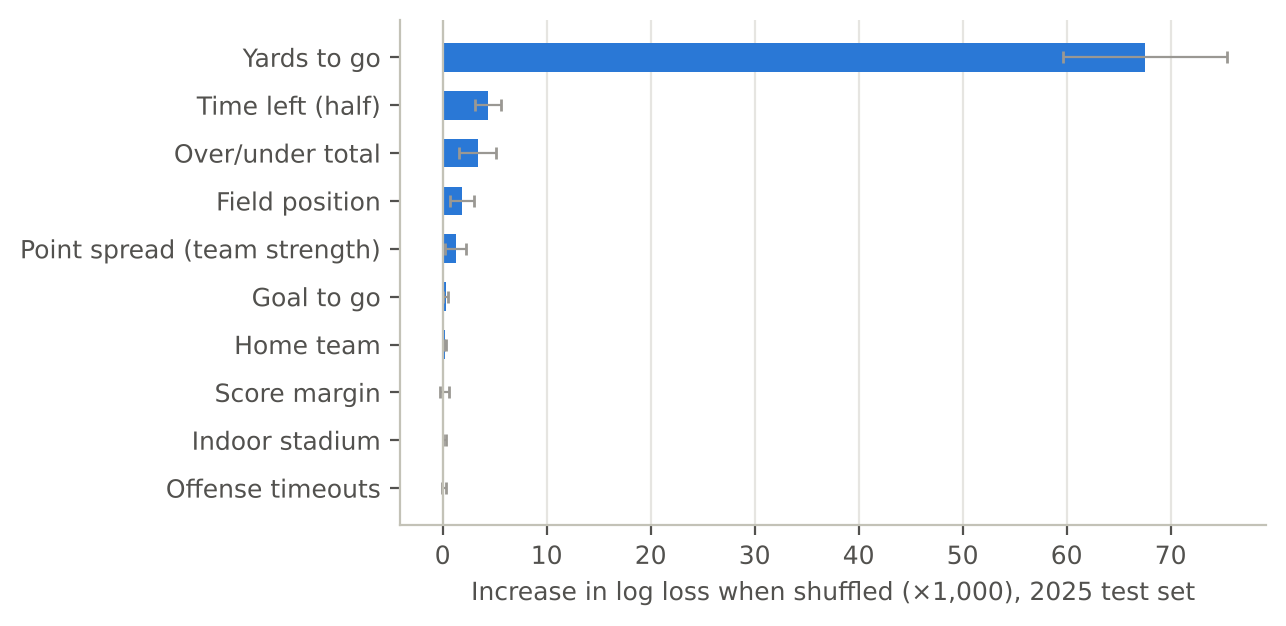

In [14]:
LABELS = {'ydstogo': 'Yards to go', 'yardline_100': 'Field position', 'score_differential': 'Score margin',
          'game_seconds_remaining': 'Time left (game)', 'half_seconds_remaining': 'Time left (half)',
          'posteam_timeouts_remaining': 'Offense timeouts', 'defteam_timeouts_remaining': 'Defense timeouts',
          'goal_to_go': 'Goal to go', 'posteam_spread': 'Point spread (team strength)', 'total_line': 'Over/under total',
          'posteam_home': 'Home team', 'indoor': 'Indoor stadium', 'turf': 'Artificial turf', 'temp_f': 'Temperature',
          'wind_mph': 'Wind', 'weather_missing': 'Weather missing', 'div_game': 'Division game',
          'pass': 'Pass play (vs run)', 'shotgun': 'Shotgun formation', 'no_huddle': 'No huddle'}
top = imp.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(6.5, 3.2), dpi=200)
ax.barh([LABELS[f] for f in top.feature], top.importance * 1000, color=BLUE, height=0.6, xerr=top.sd * 1000,
        error_kw={'ecolor': GRAY, 'lw': 0.8, 'capsize': 2})
ax.axvline(0, color='#c3c2b7', lw=0.8)
ax.set_xlabel('Increase in log loss when shuffled (×1,000), 2025 test set')
ax.grid(axis='x', color='#e6e5e1', lw=0.8); ax.set_axisbelow(True)
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/fig3_importance.png'); plt.show()

## 5. RQ3 — Were teams' decisions win-maximizing?
For every regulation fourth down, estimate the win probability (WP) of each available option:
* **Go:** P(convert) × WP(after success) + (1 − P(convert)) × WP(opponent takes over at the spot)
* **Field goal:** P(make) × WP(+3, kickoff) + (1 − P(make)) × WP(opponent ball at spot of kick, or the 20)
* **Punt:** average WP over the historical distribution of opponent starting field position from that spot

Components fit from the same data: a win-probability model (XGBoost on all regulation plays), the distance-only
conversion estimate from RQ1 (see below), a field-goal make model, the distribution of yards gained beyond the marker on successful conversions,
punt outcome distributions, and the median post-kickoff starting position by season.
Options: Go always; FG when the kick would be 63 yards or shorter; punt when at least 30 yards from the end zone.
Uncertainty: a game-level bootstrap refits every component (Brill et al., 2025), and a decision is called
*confidently* suboptimal only when at least 90% of bootstrap replicates agree an alternative had higher WP.

In [15]:
d = d.sort_values(['game_id', 'play_id']).reset_index(drop=True)
elapsed = (3600 - d.game_seconds_remaining.clip(0, 3600)) / 3600
# home_opening_kickoff = 1 means the HOME team received the opening kickoff, so the AWAY team receives the second-half kickoff
d['receive_2h_ko'] = ((d.qtr <= 2) & (((d.posteam_home == 1) & (d.home_opening_kickoff == 0)) |
                                      ((d.posteam_home == 0) & (d.home_opening_kickoff == 1)))).astype(int)
WPF = ['down', 'ydstogo', 'yardline_100', 'score_differential', 'game_seconds_remaining', 'half_seconds_remaining',
       'posteam_timeouts_remaining', 'defteam_timeouts_remaining', 'posteam_spread', 'receive_2h_ko']

def add_wp_terms(x):
    el = (3600 - x.game_seconds_remaining.clip(0, 3600)) / 3600
    x = x.copy()
    x['spread_time'] = x.posteam_spread * np.exp(-4 * el)
    x['diff_time_ratio'] = x.score_differential * np.exp(4 * el)
    return x
WPX = WPF + ['spread_time', 'diff_time_ratio']
wp_plays = add_wp_terms(d[(d.qtr <= 4) & d.down.between(1, 4) & d.posteam_won.notna() & d.posteam_spread.notna()]
                        .dropna(subset=WPF))
print(f'WP training plays: {len(wp_plays):,} from {wp_plays.game_id.nunique():,} games')

# Monotonic constraints keep the model sensible where data is thin (as nflfastR does): being closer to the end zone,
# further ahead, a bigger favorite, or holding more timeouts can never lower win probability.
MONO = {'down': -1, 'ydstogo': -1, 'yardline_100': -1, 'score_differential': 1, 'posteam_timeouts_remaining': 1,
        'defteam_timeouts_remaining': -1, 'posteam_spread': 1, 'spread_time': 1, 'diff_time_ratio': 1}
def make_wp(n=300):
    return xgb.XGBClassifier(n_estimators=n, learning_rate=0.06, max_depth=5, min_child_weight=50, subsample=0.8,
                             colsample_bytree=0.9, objective='binary:logistic', tree_method='hist', n_jobs=2, random_state=SEED,
                             monotone_constraints=tuple(MONO.get(f, 0) for f in WPX))

WP training plays: 402,950 from 2,751 games


### Validate the win-probability model on held-out games (2025), against nflfastR's published spread-adjusted WP

In [16]:
t0 = time.time()
wp_tr, wp_te = wp_plays[wp_plays.season <= 2024], wp_plays[wp_plays.season == 2025]
wpm_val = make_wp().fit(wp_tr[WPX], wp_tr.posteam_won)
p_own = wpm_val.predict_proba(wp_te[WPX])[:, 1]
wp_val = pd.DataFrame({'Our WP model': scores(wp_te.posteam_won, p_own),
                       'nflfastR vegas_wp (published)': scores(wp_te.posteam_won, wp_te.vegas_wp.clip(1e-4, 1 - 1e-4))}).T
print(wp_val.round(4).to_string()); print('correlation with nflfastR vegas_wp:', round(np.corrcoef(p_own, wp_te.vegas_wp)[0, 1], 3),
                                         f'| fit time {time.time() - t0:.0f}s')
# sanity check: early-game first-and-10, tie game, near pick'em — model vs. how often teams actually won
chk = wp_te.assign(p=p_own)
chk = wp_plays.assign(p=wpm_val.predict_proba(wp_plays[WPX])[:, 1])
chk = chk[(chk.down == 1) & (chk.ydstogo == 10) & (chk.qtr == 1) & (chk.score_differential == 0) & (chk.posteam_spread.abs() <= 3)]
print(chk.groupby(pd.cut(chk.yardline_100, [0, 20, 35, 50, 65, 80, 100]))[['p', 'posteam_won']].mean().round(3).assign(n=chk.groupby(pd.cut(chk.yardline_100, [0, 20, 35, 50, 65, 80, 100])).size()).to_string())

                                Brier  LogLoss     AUC
Our WP model                   0.1593   0.4769  0.8493
nflfastR vegas_wp (published)  0.1576   0.4715  0.8510
correlation with nflfastR vegas_wp: 0.994 | fit time 3s


                  p  posteam_won     n
yardline_100                          
(0, 20]       0.618        0.626   535
(20, 35]      0.601        0.607   867
(35, 50]      0.577        0.566  1061
(50, 65]      0.543        0.537  1531
(65, 80]      0.508        0.531  1921
(80, 100]     0.499        0.500   672


### Which conversion estimate should drive decisions?
Teams choose when to go, so the attempts the models learn from are not a random sample of fourth downs.
A flexible model can extrapolate oddly into situations where teams almost never go (for example, 4th-and-7 deep in
their own territory). RQ1 found the distance-only table nearly as accurate as the best model and statistically
indistinguishable on 2025, and it cannot extrapolate on context it never saw. The decision analysis therefore uses
the distance-only estimate. The check below compares the two on fourth downs where teams punted.

In [17]:
punted = fourth[fourth.decision == 'punt']
cmp = pd.DataFrame({'ytg': punted.ydstogo.clip(upper=11),
                    'xgb': models['XGBoost'].predict_proba(punted[SIT])[:, 1],
                    'table': baseline_pred(models['Baseline'], punted)})
print('Mean conversion odds assigned to punt situations, by yards to go:')
print(cmp.groupby('ytg')[['xgb', 'table']].mean().round(3).T.to_string())
deep = punted[(punted.yardline_100 >= 85) & (punted.ydstogo.between(6, 8))]
print(f'Deep own territory (85+ yards out), 4th-and-6 to 8, n={len(deep)}: XGBoost mean '
      f"{models['XGBoost'].predict_proba(deep[SIT])[:, 1].mean():.3f} vs table {baseline_pred(models['Baseline'], deep).mean():.3f}")

Mean conversion odds assigned to punt situations, by yards to go:
ytg     1.0    2.0    3.0    4.0    5.0    6.0    7.0    8.0    9.0    10.0   11.0
xgb    0.691  0.606  0.555  0.529  0.510  0.456  0.452  0.398  0.354  0.341  0.259
table  0.670  0.573  0.513  0.487  0.474  0.399  0.421  0.351  0.306  0.282  0.207
Deep own territory (85+ yards out), 4th-and-6 to 8, n=355: XGBoost mean 0.446 vs table 0.392


### Transition inputs

In [18]:
# Median starting field position after a kickoff, by season (kickoff rules changed in 2024 and 2025)
prev_type = d.groupby('game_id').play_type.shift(1)
ko_start = d[(prev_type == 'kickoff') & d.play_type.isin(['pass', 'run']) & (d.down == 1)].groupby('season').yardline_100.median()
print('Median opponent yardline_100 after kickoff:', ko_start.to_dict())

# Punt outcomes: next offensive snap by the receiving team
nxt = d.groupby('game_id')[['posteam', 'yardline_100', 'play_type']].shift(-1)
punts = d[d.play_type == 'punt'].assign(next_pos=nxt.posteam, next_y=nxt.yardline_100, next_type=nxt.play_type)
punts = punts[(punts.next_pos == punts.defteam) & punts.next_type.isin(['pass', 'run', 'no_play', 'punt', 'field_goal', 'qb_kneel'])]
punts['opp_y'] = punts.next_y
punts['ybin'] = (punts.yardline_100.clip(30, 95) // 5) * 5
print(f'Punts with a traceable next possession: {len(punts):,}')

QS = np.linspace(0.05, 0.95, 10)   # 10 quantiles summarize each outcome distribution

def fit_components(att_df, fg_df, punt_df, wp_df, wp_trees=300):
    conv = baseline_fit(att_df)
    succ = att_df[(att_df.converted == 1) & (att_df.yardline_100 > att_df.ydstogo)]
    extra_q = np.quantile((succ.yards_gained - succ.ydstogo).clip(lower=0), QS)
    fg = LogisticRegression(max_iter=1000).fit(fg_df[['kick_distance', 'indoor', 'wind_mph']], fg_df.made)
    punt_q = punt_df.groupby('ybin').opp_y.quantile(QS).unstack()
    wp = make_wp(wp_trees).fit(wp_df[WPX], wp_df.posteam_won)
    return dict(conv=conv, extra_q=extra_q, fg=fg, punt_q=punt_q, wp=wp)

fgs = d[d.play_type == 'field_goal'].dropna(subset=['kick_distance']).assign(made=lambda x: (x.field_goal_result == 'made').astype(int))
print('FG attempts:', len(fgs), '| median kick distance - yardline_100:', (fgs.kick_distance - fgs.yardline_100).median())
FG_OFFSET = int((fgs.kick_distance - fgs.yardline_100).median())

Median opponent yardline_100 after kickoff: {2016: 75.0, 2017: 75.0, 2018: 75.0, 2019: 75.0, 2020: 75.0, 2021: 75.0, 2022: 75.0, 2023: 75.0, 2024: 70.0, 2025: 69.0}
Punts with a traceable next possession: 21,558


FG attempts: 10731 | median kick distance - yardline_100: 18.0


### Decision engine

In [19]:
fourth = fourth.drop(columns=['receive_2h_ko'], errors='ignore').merge(d[['game_id', 'play_id', 'receive_2h_ko']], on=['game_id', 'play_id'])
dec = add_wp_terms(fourth[(fourth.qtr <= 4) & fourth.posteam_spread.notna()].copy()).reset_index(drop=True)
dec['ko_y'] = dec.season.map(ko_start)
print(f'Regulation fourth-down decisions evaluated: {len(dec):,}')

def state(base, y, togo, sd, secs_used, opp=False):
    """Build the next first-down state. y = yards from the end zone of the team with the ball."""
    s = pd.DataFrame(index=base.index)
    s['down'] = 1
    s['yardline_100'] = np.clip(y, 1, 99)
    s['ydstogo'] = np.minimum(togo, s.yardline_100)
    s['game_seconds_remaining'] = (base.game_seconds_remaining - secs_used).clip(lower=0)
    s['half_seconds_remaining'] = (base.half_seconds_remaining - secs_used).clip(lower=0)
    if opp:
        s['score_differential'] = -sd
        s['posteam_timeouts_remaining'] = base.defteam_timeouts_remaining
        s['defteam_timeouts_remaining'] = base.posteam_timeouts_remaining
        s['posteam_spread'] = -base.posteam_spread
        s['receive_2h_ko'] = ((base.qtr <= 2) & (base.receive_2h_ko == 0)).astype(int)
    else:
        s['score_differential'] = sd
        s['posteam_timeouts_remaining'] = base.posteam_timeouts_remaining
        s['defteam_timeouts_remaining'] = base.defteam_timeouts_remaining
        s['posteam_spread'] = base.posteam_spread
        s['receive_2h_ko'] = base.receive_2h_ko
    return add_wp_terms(s)[WPX]

def evaluate(comp, base):
    wp = lambda st: comp['wp'].predict_proba(st)[:, 1]
    y, togo, sd = base.yardline_100.values, base.ydstogo.values, base.score_differential.values
    # ---- GO
    p_conv = baseline_pred(comp['conv'], base)
    wp_succ = np.zeros(len(base))
    for e in comp['extra_q']:
        ny = y - togo - e
        td = ny <= 0
        w_td = 1 - wp(state(base, base.ko_y, 10, sd + 7, 6, opp=True))
        w_fd = wp(state(base, ny, 10, sd, 6))
        wp_succ += np.where(td, w_td, w_fd) / len(comp['extra_q'])
    wp_fail = 1 - wp(state(base, 100 - y, 10, sd, 6, opp=True))
    wp_go = p_conv * wp_succ + (1 - p_conv) * wp_fail
    # ---- FIELD GOAL
    kd = y + FG_OFFSET
    p_make = comp['fg'].predict_proba(pd.DataFrame({'kick_distance': kd, 'indoor': base.indoor.values, 'wind_mph': base.wind_mph.values}))[:, 1]
    wp_make = 1 - wp(state(base, base.ko_y, 10, sd + 3, 5, opp=True))
    wp_miss = 1 - wp(state(base, np.minimum(80, 100 - (y + FG_OFFSET - 10)), 10, sd, 5, opp=True))
    wp_fg = p_make * wp_make + (1 - p_make) * wp_miss
    # ---- PUNT
    pq = comp['punt_q'].reindex((np.clip(y, 30, 95) // 5) * 5).values
    wp_punt = np.zeros(len(base))
    for j in range(pq.shape[1]):
        wp_punt += (1 - wp(state(base, pq[:, j], 10, sd, 8, opp=True))) / pq.shape[1]
    return pd.DataFrame({'go': wp_go, 'field_goal': wp_fg, 'punt': wp_punt, 'p_conv': p_conv,
                         'fg_ok': kd <= 63, 'punt_ok': y >= 30}, index=base.index)

def masked(e, chosen=None):
    # options available to recommend; the option actually chosen is always kept so it can be scored
    arr = e[['go', 'field_goal', 'punt']].to_numpy().copy()
    ok = np.column_stack([np.ones(len(e), bool), e.fg_ok.values, e.punt_ok.values])
    if chosen is not None: ok[np.arange(len(e)), chosen] = True
    arr[~ok] = np.nan
    return arr

Regulation fourth-down decisions evaluated: 39,102


### Point estimates (all components fit on 2016–2025)

In [20]:
t0 = time.time()
comp_full = fit_components(att, fgs, punts, wp_plays)
ev = evaluate(comp_full, dec)
opts = ['go', 'field_goal', 'punt']
chosen_idx = dec.decision.map({o: i for i, o in enumerate(opts)}).values
arr = masked(ev, chosen_idx)
ev['best'] = np.array(opts)[np.nanargmax(arr, axis=1)]
ev['chosen'] = dec.decision.values
ev['wp_chosen'] = arr[np.arange(len(arr)), chosen_idx]
ev['wp_best'] = np.nanmax(arr, axis=1)
ev['wp_lost'] = ev.wp_best - ev.wp_chosen
ev = pd.concat([dec[['game_id', 'play_id', 'season', 'posteam', 'qtr', 'ydstogo', 'yardline_100', 'score_differential', 'wp']].reset_index(drop=True), ev], axis=1)
print(f'evaluation time {time.time() - t0:.0f}s')
print('Chosen option had missing WP (option judged unavailable, e.g. punt inside 30):', ev.wp_chosen.isna().sum())
print(pd.crosstab(ev.chosen, ev.best, margins=True).to_string())

evaluation time 6s
Chosen option had missing WP (option judged unavailable, e.g. punt inside 30): 0
best        field_goal     go   punt    All
chosen                                     
field_goal        5001   4487    224   9712
go                 478   5790    735   7003
punt               436   8248  13703  22387
All               5915  18525  14662  39102


Grid of situations for Figure 5: tied game, first quarter, even teams (scored inside the bootstrap too)

In [21]:
grid_rows = []
for yl in range(1, 100):
    for t in range(1, 11):
        if t > yl: continue
        grid_rows.append({'yardline_100': yl, 'ydstogo': t})
gdf = pd.DataFrame(grid_rows)
neutral = {'score_differential': 0, 'game_seconds_remaining': 3300, 'half_seconds_remaining': 1500, 'qtr': 1,
           'posteam_timeouts_remaining': 3, 'defteam_timeouts_remaining': 3, 'posteam_spread': 0, 'total_line': 45,
           'posteam_home': 1, 'indoor': 0, 'turf': 0, 'temp_f': 60, 'wind_mph': 5, 'weather_missing': 0, 'div_game': 0,
           'receive_2h_ko': 0, 'ko_y': ko_start[2025]}
for k, v in neutral.items(): gdf[k] = v
gdf['goal_to_go'] = (gdf.ydstogo == gdf.yardline_100).astype(int)
gdf = add_wp_terms(gdf)

### Game-level bootstrap: refit every component B times

In [22]:
B = int(os.environ.get('BOOT_B', 50))
games = d.game_id.unique()
boot_best = np.zeros((B, len(dec)), dtype=np.int8)
boot_gap = np.zeros((B, len(dec)), dtype=np.float32)
grid_best = np.zeros((B, len(gdf)), dtype=np.int8)
t0 = time.time()
for b in range(B):
    gs = pd.Series(rng.choice(games, len(games)), name='game_id')
    take = lambda df: df.merge(gs, on='game_id')   # duplicates resampled games
    comp_b = fit_components(take(att), take(fgs), take(punts), take(wp_plays), wp_trees=200)
    e = evaluate(comp_b, dec)
    arr = masked(e, chosen_idx)
    w_ch = arr[np.arange(len(arr)), chosen_idx]
    boot_best[b] = np.nanargmax(arr, axis=1)
    boot_gap[b] = np.nanmax(arr, axis=1) - w_ch
    grid_best[b] = np.nanargmax(masked(evaluate(comp_b, gdf)), axis=1)
    if b % 10 == 9: print(f'  replicate {b + 1}/{B}  ({time.time() - t0:.0f}s)')
ev['share_alt_better'] = (boot_best != chosen_idx).mean(axis=0)
ev['wp_lost_lo'] = np.nanpercentile(boot_gap, 5, axis=0)
ev['confident_bad'] = ev.share_alt_better >= 0.90
ev['confident_good'] = ev.share_alt_better <= 0.10
ev['toss_up'] = ~(ev.confident_bad | ev.confident_good)
ev['kick_when_go'] = ev.confident_bad & ev.chosen.isin(['punt', 'field_goal']) & (ev.best == 'go')
ev['go_when_kick'] = ev.confident_bad & (ev.chosen == 'go')

  replicate 10/50  (47s)


  replicate 20/50  (92s)


  replicate 30/50  (137s)


  replicate 40/50  (183s)


  replicate 50/50  (228s)


### Results

In [23]:
summ = pd.DataFrame({
    'decisions': ev.groupby('season').size(),
    'suboptimal (point estimate) %': ev.assign(x=ev.best != ev.chosen).groupby('season').x.mean() * 100,
    'confidently suboptimal %': ev.groupby('season').confident_bad.mean() * 100,
    'kicked when go confidently better %': ev.groupby('season').kick_when_go.mean() * 100,
    'went when kick confidently better %': ev.groupby('season').go_when_kick.mean() * 100,
    'toss-up %': ev.groupby('season').toss_up.mean() * 100,
    'WP lost per game (pts, confident errors)': ev[ev.confident_bad].groupby('season').wp_lost.sum() / ev.groupby('season').game_id.nunique() * 100 / 2})
print(summ.round(2).to_string())
overall = {
    'decisions': len(ev),
    'suboptimal_point_pct': (ev.best != ev.chosen).mean() * 100,
    'confident_bad_pct': ev.confident_bad.mean() * 100,
    'toss_up_pct': ev.toss_up.mean() * 100,
    'kick_when_go_share_of_confident_bad': ev.kick_when_go.sum() / ev.confident_bad.sum() * 100,
    'median_wp_lost_confident_bad_pts': ev[ev.confident_bad].wp_lost.median() * 100}
print({k: round(v, 2) for k, v in overall.items()})

        decisions  suboptimal (point estimate) %  confidently suboptimal %  kicked when go confidently better %  went when kick confidently better %  toss-up %  WP lost per game (pts, confident errors)
season                                                                                                                                                                                                   
2016         3867                          39.28                     19.60                                17.64                                 1.01      43.32                                      4.11
2017         3999                          39.08                     18.90                                17.08                                 0.98      43.06                                      3.57
2018         3747                          37.92                     17.69                                15.69                                 0.85      43.85                                 

In [24]:
# Where are the confidently missed go-for-it chances?
kg = ev[ev.kick_when_go]
print('Confident kick-when-go cases by yards to go:'); print(kg.ydstogo.clip(upper=6).value_counts().sort_index().to_string())
print('by field position (yards from end zone):'); print(pd.cut(kg.yardline_100, [0, 20, 40, 60, 100]).value_counts().sort_index().to_string())
fourth_and_1_short = ev[(ev.ydstogo == 1)]
print('4th-and-1: model recommends go in', round((fourth_and_1_short.best == 'go').mean() * 100, 1), '% | teams went in',
      round((fourth_and_1_short.chosen == 'go').mean() * 100, 1), '%')
team25 = ev[ev.season == 2025].groupby('posteam').agg(conf_bad=('confident_bad', 'mean'), kick_when_go=('kick_when_go', 'sum')).sort_values('conf_bad')
print('2025 team range, confidently suboptimal %:', round(team25.conf_bad.min() * 100, 1), '-', round(team25.conf_bad.max() * 100, 1))

Confident kick-when-go cases by yards to go:
ydstogo
1.0    1068
2.0     923
3.0     760
4.0     755
5.0     729
6.0    1631
by field position (yards from end zone):
yardline_100
(0, 20]      1217
(20, 40]      810
(40, 60]     1741
(60, 100]    2098
4th-and-1: model recommends go in 90.5 % | teams went in 62.2 %
2025 team range, confidently suboptimal %: 8.0 - 24.1


### Figure 4 — Confidently suboptimal decisions by season

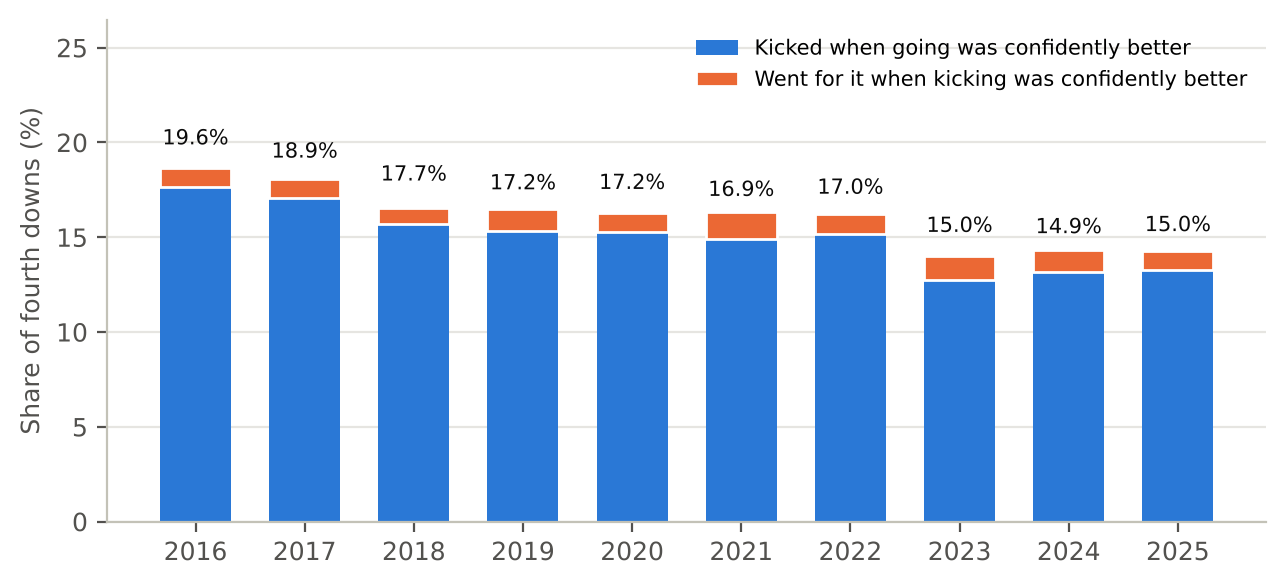

In [25]:
fig, ax = plt.subplots(figsize=(6.5, 3.0), dpi=200)
x = summ.index.values
ax.bar(x, summ['kicked when go confidently better %'], color=BLUE, width=0.65, label='Kicked when going was confidently better')
ax.bar(x, summ['went when kick confidently better %'], bottom=summ['kicked when go confidently better %'], color=ORANGE, width=0.65,
       label='Went for it when kicking was confidently better', edgecolor='white', linewidth=1)
for xi, v in zip(x, summ['confidently suboptimal %']):
    ax.text(xi, v + 0.3, f'{v:.1f}%', ha='center', fontsize=7.5, color=INK)
ax.set_ylabel('Share of fourth downs (%)'); ax.set_xticks(x)
ax.grid(axis='y', color='#e6e5e1', lw=0.8); ax.set_axisbelow(True); ax.legend(frameon=False, fontsize=7.5, loc='upper right')
ax.set_ylim(0, summ['confidently suboptimal %'].max() * 1.35)
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/fig4_suboptimal_by_season.png'); plt.show()

### Figure 5 — Decision map for a tied first-quarter game, with bootstrap confidence

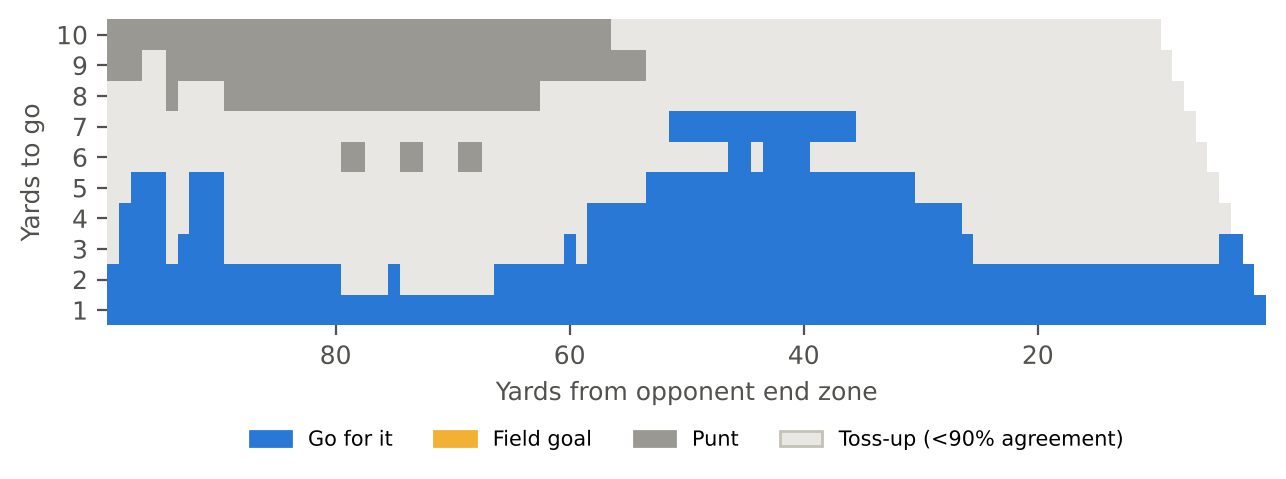

{'toss_up': 0.534, 'go': 0.338, 'punt': 0.128}
Midfield, tied Q1: confident go up to 7 yards; categories at midfield: {1: 'go', 2: 'go', 3: 'go', 4: 'go', 5: 'go', 6: 'toss_up', 7: 'go', 8: 'toss_up', 9: 'toss_up', 10: 'toss_up'}
Own 25: {1: 'go', 2: 'go', 3: 'toss_up', 4: 'toss_up', 5: 'toss_up', 6: 'toss_up', 7: 'toss_up', 8: 'punt', 9: 'punt', 10: 'punt'}


In [26]:
shares = np.stack([(grid_best == i).mean(axis=0) for i in range(3)], axis=1)
cat = np.where(shares[:, 0] >= 0.9, 0, np.where(shares[:, 1] >= 0.9, 1, np.where(shares[:, 2] >= 0.9, 2, 3)))
gdf['best'] = np.array(['go', 'field_goal', 'punt', 'toss_up'])[cat]
mat = np.full((10, 99), np.nan)
for yl, t, c in zip(gdf.yardline_100, gdf.ydstogo, cat): mat[int(t) - 1, int(yl) - 1] = c
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
fig, ax = plt.subplots(figsize=(6.5, 2.6), dpi=200)
ax.imshow(mat, aspect='auto', cmap=ListedColormap([BLUE, '#f2b134', '#9a9893', '#e8e7e3']), vmin=-0.5, vmax=3.5, origin='lower',
          extent=[0.5, 99.5, 0.5, 10.5], interpolation='nearest')
ax.set_xlabel('Yards from opponent end zone'); ax.set_ylabel('Yards to go'); ax.invert_xaxis(); ax.set_yticks(range(1, 11))
ax.legend(handles=[Patch(color=BLUE, label='Go for it'), Patch(color='#f2b134', label='Field goal'), Patch(color='#9a9893', label='Punt'),
                   Patch(facecolor='#e8e7e3', edgecolor='#c3c2b7', label='Toss-up (<90% agreement)')],
          frameon=False, fontsize=7.5, loc='upper center', bbox_to_anchor=(0.5, -0.28), ncol=4)
for sp in ['left', 'bottom']: ax.spines[sp].set_visible(False)
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/fig5_decision_map.png'); plt.show()
print(gdf.best.value_counts(normalize=True).round(3).to_dict())
print('Midfield, tied Q1: confident go up to', gdf[(gdf.yardline_100 == 50) & (gdf.best == 'go')].ydstogo.max(), 'yards; categories at midfield:', gdf[gdf.yardline_100 == 50].set_index('ydstogo').best.to_dict())
print('Own 25:', gdf[gdf.yardline_100 == 75].set_index('ydstogo').best.to_dict())

In [27]:
ev.to_csv(os.path.join(FIG_DIR, 'decision_evaluations.csv'), index=False)
print('Saved per-play decision evaluations.')

Saved per-play decision evaluations.


## 6. Extensions — analyses behind the audience questions
These cells answer the ten audience questions proposed in Milestone 2. They reuse the fitted components,
the decision table `ev`, and the bootstrap arrays from Section 5, so they must run after it.

### Q2 — Is the 90% bootstrap threshold the right line? (threshold sensitivity)

In [28]:
thr_rows = []
for t in [0.75, 0.80, 0.90, 0.95]:
    bad = ev.share_alt_better >= t
    good = ev.share_alt_better <= round(1 - t, 2)
    thr_rows.append({'threshold': t, 'confidently suboptimal %': bad.mean() * 100,
                     'toss-up %': (~(bad | good)).mean() * 100,
                     '2016 %': bad[ev.season == 2016].mean() * 100, '2025 %': bad[ev.season == 2025].mean() * 100,
                     'kick-when-go share of errors %': (bad & ev.chosen.isin(['punt', 'field_goal']) & (ev.best == 'go')).sum() / bad.sum() * 100})
thr = pd.DataFrame(thr_rows)
thr['threshold'] = thr.threshold.map('{:.0%}'.format)
print(thr.round(1).to_string(index=False))

threshold  confidently suboptimal %  toss-up %  2016 %  2025 %  kick-when-go share of errors %
      75%                      25.8       24.7    28.2    23.6                            86.5
      80%                      23.5       29.4    25.9    21.6                            87.1
      90%                      16.9       43.5    19.6    15.0                            88.7
      95%                      11.5       55.9    14.0    10.2                            89.6


### Q3 — How much could selection bias in attempts distort the conclusions? (conversion-odds stress test)
Teams go for it mostly when they expect to convert, so observed rates may overstate the odds in situations where they
usually kick. Shade every conversion probability down by 5 and 10 points and re-run the point-estimate decisions.

In [29]:
def shaded(comp, delta):
    table, prior = comp['conv']
    c = dict(comp); c['conv'] = ({k: v - delta for k, v in table.items()}, prior - delta); return c
sel_rows = []
for delta in [0.0, 0.05, 0.10]:
    e = evaluate(shaded(comp_full, delta), dec)
    a = masked(e, chosen_idx)
    best = np.array(opts)[np.nanargmax(a, axis=1)]
    kicked = dec.decision.isin(['punt', 'field_goal']).values
    sel_rows.append({'conversion odds shaded by': f'-{int(delta * 100)} pts', 'model recommends go %': (best == 'go').mean() * 100,
                     'kicks where go was better %': (kicked & (best == 'go')).sum() / kicked.sum() * 100,
                     '4th-and-1 go recommended %': (best[dec.ydstogo.values == 1] == 'go').mean() * 100,
                     'teams actually went %': (dec.decision == 'go').mean() * 100})
sel = pd.DataFrame(sel_rows)
print(sel.round(1).to_string(index=False))

conversion odds shaded by  model recommends go %  kicks where go was better %  4th-and-1 go recommended %  teams actually went %
                   -0 pts                   47.4                         39.7                        90.5                   17.9
                   -5 pts                   39.2                         30.8                        86.1                   17.9
                  -10 pts                   31.3                         22.8                        80.0                   17.9


### Q4 — Does the fourth-and-1 recommendation hold late in close games?

In [30]:
e1 = ev.merge(dec[['game_id', 'play_id', 'game_seconds_remaining']], on=['game_id', 'play_id'])
e1 = e1[e1.ydstogo == 1]
def f1(x):
    return pd.Series({'n': len(x), 'model says go %': (x.best == 'go').mean() * 100,
                      'teams went %': (x.chosen == 'go').mean() * 100})
seg = pd.Series(np.select([(e1.qtr == 4) & (e1.score_differential.abs() <= 8) & (e1.game_seconds_remaining <= 300),
                           (e1.qtr == 4) & (e1.score_differential.abs() <= 8)], ['Q4 last 5 min, within 8', 'Q4, within 8 (before last 5 min)'], 'All other 4th-and-1'), index=e1.index)
q4 = e1.groupby(seg).apply(f1)
q4.loc['All 4th-and-1'] = f1(e1)
print(q4.round(1).to_string())
late = e1[(e1.qtr == 4) & (e1.score_differential.abs() <= 8) & (e1.game_seconds_remaining <= 300)]
print('\nLate & close by score state:')
print(late.groupby(np.sign(late.score_differential).map({-1: 'trailing', 0: 'tied', 1: 'leading'})).apply(f1).round(1).to_string())

                                       n  model says go %  teams went %
All other 4th-and-1               3736.0             90.6          62.4
Q4 last 5 min, within 8            338.0             86.1          60.4
Q4, within 8 (before last 5 min)   355.0             93.8          62.0
All 4th-and-1                     4429.0             90.5          62.2

Late & close by score state:
                        n  model says go %  teams went %
score_differential                                      
leading             144.0             83.3          41.0
tied                 45.0             75.6          42.2
trailing            149.0             91.9          84.6


### Q5 — Does the model account for team quality? (conversion by point spread)

In [31]:
att['fav_group'] = pd.cut(att.posteam_spread, [-30, -6.5, -2.5, 2.5, 6.5, 30],
                          labels=['Underdog 7+', 'Underdog 3-6.5', 'Near even', 'Favorite 3-6.5', 'Favorite 7+'])
fav = att.groupby('fav_group', observed=True).agg(n=('converted', 'size'), conv=('converted', 'mean'), mean_ytg=('ydstogo', 'mean'))
fav['table expected'] = att.groupby('fav_group', observed=True).apply(lambda x: baseline_pred(comp_full['conv'], x).mean())
print(fav.round(3).to_string())
print('FG model inputs:', ['kick_distance', 'indoor', 'wind_mph'], '| coefficients:', comp_full['fg'].coef_.round(3), comp_full['fg'].intercept_.round(3))

                   n   conv  mean_ytg  table expected
fav_group                                            
Underdog 7+     1402  0.477     4.853           0.502
Underdog 3-6.5  2012  0.522     4.368           0.521
Near even       1211  0.539     3.866           0.537
Favorite 3-6.5  1420  0.564     3.575           0.550
Favorite 7+      740  0.581     2.826           0.578
FG model inputs: ['kick_distance', 'indoor', 'wind_mph'] | coefficients: [[-0.105  0.119 -0.02 ]] [6.237]


### Q6 — How did the 2024–2025 kickoff rule changes affect the punt and field-goal comparisons?
The engine already uses each season's median start after a kickoff. Re-score 2024–2025 decisions as if
kickoffs still started at the old median (own 25) and count how many recommendations change.

In [32]:
rec = dec[dec.season >= 2024].copy()
idx = rec.index.values
a_new = masked(evaluate(comp_full, rec), chosen_idx[idx])
rec_old = rec.assign(ko_y=75.0)
a_old = masked(evaluate(comp_full, rec_old), chosen_idx[idx])
b_new, b_old = np.array(opts)[np.nanargmax(a_new, 1)], np.array(opts)[np.nanargmax(a_old, 1)]
print('Median kickoff start by season (yards from own end zone = 100 - yardline_100):', {k: 100 - v for k, v in ko_start.to_dict().items()})
print(f'2024-25 decisions: {len(rec):,} | recommendation changes if kickoffs started at the 25: {(b_new != b_old).mean() * 100:.1f}%')
print(pd.crosstab(pd.Series(b_old, name='old kickoff rules'), pd.Series(b_new, name='new kickoff rules')).to_string())
for o in range(3):
    print(f'mean WP change for {opts[o]}: {np.nanmean(a_new[:, o] - a_old[:, o]) * 100:+.2f} pts')

Median kickoff start by season (yards from own end zone = 100 - yardline_100): {2016: 25.0, 2017: 25.0, 2018: 25.0, 2019: 25.0, 2020: 25.0, 2021: 25.0, 2022: 25.0, 2023: 25.0, 2024: 30.0, 2025: 31.0}
2024-25 decisions: 7,955 | recommendation changes if kickoffs started at the 25: 2.5%
new kickoff rules  field_goal    go  punt
old kickoff rules                        
field_goal               1170   175    21
go                          0  3710     0
punt                        0     0  2879
mean WP change for go: -0.03 pts
mean WP change for field_goal: -0.49 pts
mean WP change for punt: +0.00 pts


### Q7 — Why do runs convert more than passes on fourth-and-1?

In [33]:
f1a = att[att.ydstogo == 1].copy()
f1a['call'] = np.select([(f1a['pass'] == 0) & (f1a.shotgun == 0), (f1a['pass'] == 0) & (f1a.shotgun == 1)],
                        ['Run, under center', 'Run, shotgun'], 'Pass')
t7 = f1a.groupby('call').agg(n=('converted', 'size'), conv=('converted', 'mean'))
print(t7.round(3).to_string())
for s, g in f1a.groupby(f1a.season >= 2021):
    print('2021-25' if s else '2016-20', g.groupby(g['pass']).converted.agg(['size', 'mean']).round(3).to_dict())

                      n   conv
call                          
Pass                762  0.580
Run, shotgun        385  0.686
Run, under center  1584  0.708
2016-20 {'size': {0.0: 786, 1.0: 303}, 'mean': {0.0: 0.677, 1.0: 0.578}}
2021-25 {'size': {0.0: 1183, 1.0: 459}, 'mean': {0.0: 0.721, 1.0: 0.582}}


### Q8 — How much does a confidently wrong decision cost over a season?

In [34]:
gp = ev.groupby(['season', 'posteam']).game_id.nunique().rename('games')
lost = ev[ev.confident_bad].groupby(['season', 'posteam']).agg(errors=('wp_lost', 'size'), wins_lost=('wp_lost', 'sum'))
ts = pd.concat([gp, lost], axis=1).fillna(0)
ts['wins_lost_per_17'] = ts.wins_lost / ts.games * 17
print('Expected wins lost per team-season to confidently suboptimal calls (scaled to 17 games):')
print(ts.groupby('season').wins_lost_per_17.describe()[['mean', '50%', 'min', 'max']].round(2).to_string())
print('Errors per team-season:', ts.groupby('season').errors.mean().round(1).to_dict())
print(f'Overall mean {ts.wins_lost_per_17.mean():.2f} wins/season; median cost per confident error {ev[ev.confident_bad].wp_lost.median() * 100:.1f} WP pts')

Expected wins lost per team-season to confidently suboptimal calls (scaled to 17 games):
        mean   50%   min   max
season                        
2016    0.70  0.73  0.16  1.22
2017    0.61  0.59  0.35  1.14
2018    0.52  0.51  0.27  0.97
2019    0.53  0.47  0.18  0.97
2020    0.49  0.47  0.14  0.88
2021    0.47  0.43  0.13  1.02
2022    0.56  0.52  0.17  1.12
2023    0.48  0.50  0.15  0.91
2024    0.47  0.44  0.18  0.89
2025    0.46  0.43  0.18  0.81
Errors per team-season: {2016: 23.7, 2017: 23.6, 2018: 20.7, 2019: 20.4, 2020: 19.3, 2021: 20.8, 2022: 21.4, 2023: 19.7, 2024: 18.6, 2025: 18.7}
Overall mean 0.53 wins/season; median cost per confident error 2.1 WP pts


### Q9 — Could this run on the sideline in real time?

In [35]:
t0 = time.perf_counter(); _ = evaluate(comp_full, dec); t_all = time.perf_counter() - t0
one = dec.iloc[[1000]]
t0 = time.perf_counter()
for _ in range(20): evaluate(comp_full, one)
t_one = (time.perf_counter() - t0) / 20
print(f'All {len(dec):,} decisions: {t_all:.2f}s ({t_all / len(dec) * 1000:.3f} ms each, batched) | one situation alone: {t_one * 1000:.0f} ms')

All 39,102 decisions: 2.59s (0.066 ms each, batched) | one situation alone: 238 ms


### Q10 — Which teams improved most, and does better decision-making show up in wins?

In [36]:
games_tbl = d.drop_duplicates('game_id')[['game_id', 'season', 'season_type', 'home_team', 'away_team', 'result']]
games_tbl = games_tbl[games_tbl.season_type == 'REG']
rows = pd.concat([games_tbl.assign(team=games_tbl.home_team, w=np.sign(games_tbl.result)),
                  games_tbl.assign(team=games_tbl.away_team, w=-np.sign(games_tbl.result))])
rows['win'] = rows.w.map({1: 1.0, 0: 0.5, -1: 0.0})
winpct = rows.groupby(['season', 'team']).win.mean().rename('win_pct')
team_bad = ev.groupby(['season', 'posteam']).confident_bad.mean().mul(100).rename('bad_pct')
tw = pd.concat([team_bad, winpct.rename_axis(['season', 'posteam'])], axis=1).dropna().reset_index()
early = tw[tw.season <= 2018].groupby('posteam').bad_pct.mean()
late_ = tw[tw.season >= 2023].groupby('posteam').bad_pct.mean()
chg = pd.DataFrame({'2016-18 %': early, '2023-25 %': late_}).dropna()
chg['change (pts)'] = chg['2023-25 %'] - chg['2016-18 %']
chg = chg.sort_values('change (pts)')
print('Most improved (largest drop in confidently suboptimal share):'); print(chg.head(5).round(1).to_string())
print('Least improved:'); print(chg.tail(5).round(1).to_string())
print(f'Teams improving: {(chg["change (pts)"] < 0).sum()} of {len(chg)}')
r_same = tw[['bad_pct', 'win_pct']].corr().iloc[0, 1]
tw['win_next'] = tw.groupby('posteam').win_pct.shift(-1)
r_next = tw[['bad_pct', 'win_next']].dropna().corr().iloc[0, 1]
tw_ = tw.merge(ts.reset_index().rename(columns={'posteam': 'posteam'})[['season', 'posteam', 'wins_lost_per_17']], on=['season', 'posteam'])
r_lost = tw_[['wins_lost_per_17', 'win_pct']].corr().iloc[0, 1]
print(f'Correlation, team-season confidently suboptimal % vs same-season win %: {r_same:.2f} | vs next-season win %: {r_next:.2f}')
print(f'Correlation, expected wins lost vs same-season win %: {r_lost:.2f}')
chg.to_csv(os.path.join(FIG_DIR, 'team_improvement.csv'))

Most improved (largest drop in confidently suboptimal share):
         2016-18 %  2023-25 %  change (pts)
posteam                                    
SF            24.4       14.3         -10.1
HOU           23.1       13.5          -9.7
BUF           19.9       10.8          -9.1
NYJ           26.1       17.4          -8.7
DET           17.7       10.5          -7.2
Least improved:
         2016-18 %  2023-25 %  change (pts)
posteam                                    
NE            17.3       17.8           0.5
DAL           14.5       15.6           1.0
MIN           15.8       16.8           1.1
PIT           15.5       17.6           2.0
CAR           15.3       18.6           3.3
Teams improving: 27 of 32
Correlation, team-season confidently suboptimal % vs same-season win %: -0.47 | vs next-season win %: -0.28
Correlation, expected wins lost vs same-season win %: -0.35


### Figure 6 — Team decision quality, 2016–18 versus 2023–25

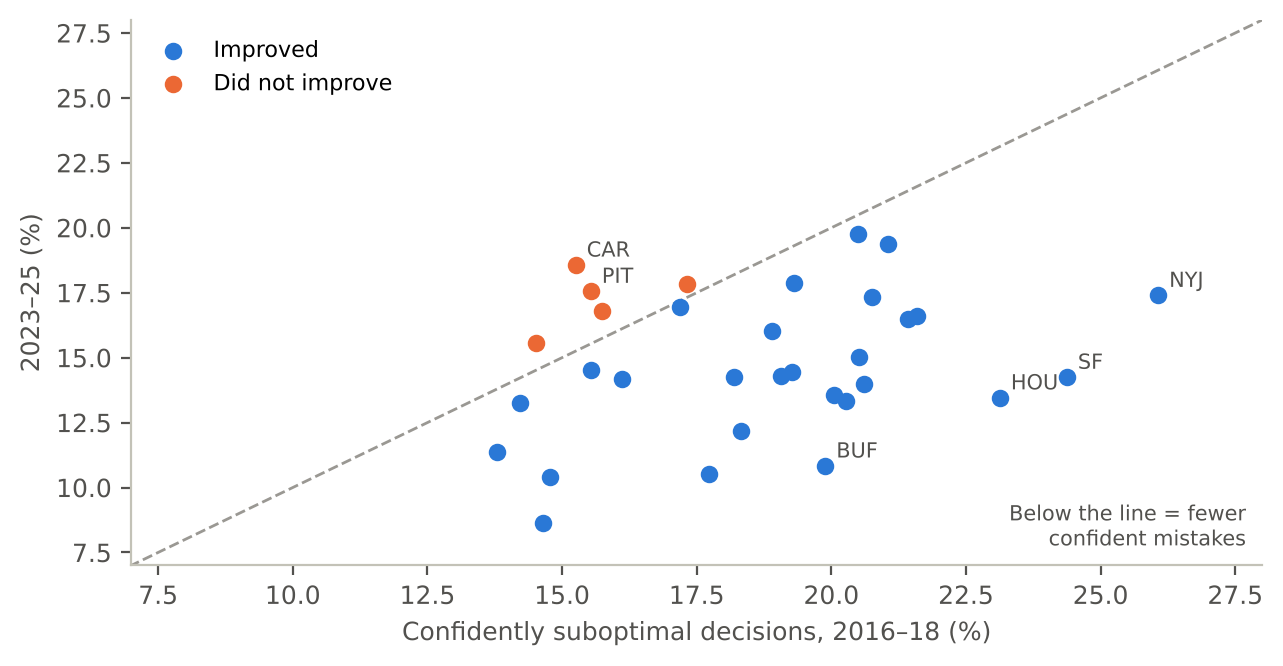

In [37]:
fig, ax = plt.subplots(figsize=(6.5, 3.4), dpi=200)
lim = (min(chg.min().min(), 0) - 1, chg[['2016-18 %', '2023-25 %']].max().max() + 2)
ax.plot([5, 30], [5, 30], color=GRAY, lw=1, ls='--')
better = chg['change (pts)'] < 0
ax.scatter(chg.loc[better, '2016-18 %'], chg.loc[better, '2023-25 %'], s=28, color=BLUE, label='Improved', zorder=3)
ax.scatter(chg.loc[~better, '2016-18 %'], chg.loc[~better, '2023-25 %'], s=28, color=ORANGE, label='Did not improve', zorder=3)
for t in list(chg.head(4).index) + list(chg.tail(2).index):
    ax.annotate(t, (chg.loc[t, '2016-18 %'], chg.loc[t, '2023-25 %']), xytext=(4, 3), textcoords='offset points', fontsize=7.5, color=INK2)
lo = np.floor(chg[['2016-18 %', '2023-25 %']].min().min()) - 1; hi = np.ceil(chg[['2016-18 %', '2023-25 %']].max().max()) + 1
ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
ax.set_xlabel('Confidently suboptimal decisions, 2016–18 (%)'); ax.set_ylabel('2023–25 (%)')
ax.text(hi - 0.3, lo + 0.5, 'Below the line = fewer\nconfident mistakes', ha='right', va='bottom', fontsize=7.5, color=INK2)
ax.legend(frameon=False, loc='upper left', fontsize=8)
fig.tight_layout(); fig.savefig(os.path.join(FIG_DIR, 'fig6_team_improvement.png'), bbox_inches='tight'); plt.show()